Measure the gap between the average head and the head in the wells for different pumping rates and different settings.

In [30]:
from typing import List
import numpy as np
import scipy.sparse as sp
import matplotlib.pyplot as plt
from tqdm import trange
import copy
import os
import json

import cvxpy as cp
import gurobipy as gp

from Components.RecedingHorizon import RecedingHorizon
from Components.System import SimpleSquareExample
from Components.Model import IrrigationSchedulingModel, IrrigationSchedulingCost
from Components.Controllers import TimeVaryingCost_LQRc_RHG, LQRc_welfare
from Components.Solver import fbrs

In [2]:
# Reload scripts when executed
%load_ext autoreload
%autoreload 2

np.set_printoptions(linewidth=np.inf)

In [52]:
repo = "run_data/setting_study"

well_pos = []
data = {"wells": {}, "yield_sensitivity": {}, "cost_difference": {}, "cost_improvement": {}}
for name in os.listdir(repo):
    if name[:3] != 'run':
        continue
    # Open file
    with np.load(os.path.join(repo, name, "game/result_data.npz")) as data_si:
        with np.load(os.path.join(repo, name, "welfare/result_data.npz")) as data_wf:
            with open(os.path.join(repo, name, "game/model_parameters_combination.json"), 'r') as f:
                setting = json.load(f)
                data["wells"][name] = setting['wells']['pos']
                data["yield_sensitivity"][name] = setting['costs']['yield_sensitivity']
                data["cost_difference"][name] = np.sum(data_wf['model_profit']) - np.sum(data_si['model_profit'])
                data["cost_improvement"][name] = (np.sum(data_wf['model_profit']) - np.sum(data_si['model_profit']))/abs(np.sum(data_si['model_profit']))

In [33]:
max(data["cost_difference"], key=data["cost_difference"].get), data["cost_difference"][max(data["cost_difference"], key=data["cost_difference"].get)]

('run_20250705-033052', np.float64(525.6662732481782))

In [34]:
data["cost_improvement"][max(data["cost_difference"], key=data["cost_difference"].get)]

np.float64(0.005241908846410609)

In [35]:
max(data["cost_improvement"], key=data["cost_improvement"].get), data["cost_improvement"][max(data["cost_improvement"], key=data["cost_improvement"].get)]

('run_20250705-083453', np.float64(0.005924656843228238))

In [53]:
np.unique(np.fromiter(data["yield_sensitivity"].values(), dtype=object)).shape

(369,)

In [62]:
np.array(np.fromiter(data["yield_sensitivity"].values(), dtype=object)[0]).mean()

np.float64(0.5166666666666667)

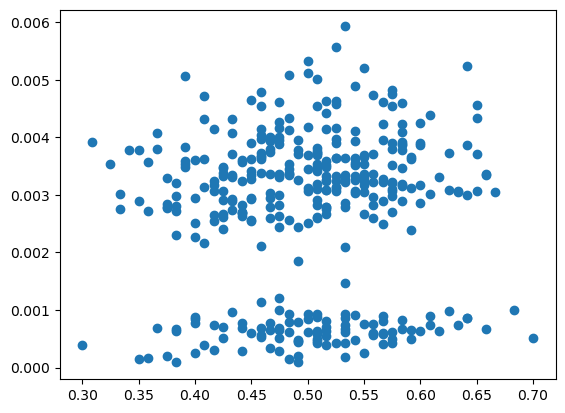

In [69]:
plt.scatter([np.array(p_y).mean() for p_y in data["yield_sensitivity"].values()], np.fromiter(data["cost_improvement"].values(), dtype=float))